In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
df = pd.read_csv('exoplanet_data.csv', comment='#')
df.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
1,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
2,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
3,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
4,DMPP-1 c,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05


In [4]:
print("the shape of teh data set is 5 by 92, meaning there are 5 rows and 92 columns. sy_snum, pl_controv_flag, sy_vmagerr2, sy_kmag, sy_kmagerr1")

the shape of teh data set is 5 by 92, meaning there are 5 rows and 92 columns. sy_snum, pl_controv_flag, sy_vmagerr2, sy_kmag, sy_kmagerr1


In [5]:
# Table Label: Planet Name
# Database Column Name: pl_name
# Description: Planet name most commonly used in the literature.
# My Description: Planet Name
# Table Label: Host Name
# Database Column Name: hostname
# Description: Stellar name most commonly used in the literature.
# My Description: Star Name
# Table Label: Discovery Method
# Database Column Name: discoverymethod
# Description: Method by which the planet was first identified.
# My Description: By telescope or other method
# Table Label: Spectral Type
# Database Column Name: st_spectype
# Description: Classification of the star based on their spectral characteristics following the Morgan-Keenan system.
# My Description: H-R Diagram sort of
# Table Label: Equilibrium Temperature [K]
# Database Column Name: pl_eqt
# Description: The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body.
# My Description: Temperature of teh planet
# Table Label: Planet Mass or Mass*sin(i) [Jupiter Mass]
# Database Column Name: pl_bmassj
# Description: Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses.
# My Description: Mass in jupiters

In [7]:
selected_columns = [
    'pl_name', 
    'hostname', 
    'discoverymethod', 
    'st_spectype', 
    'pl_eqt', 
    'pl_bmassj'
]
df_small = df[selected_columns]
df_filtered = df_small.dropna()
df_filtered

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
2,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
5,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
7,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
10,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000
...,...,...,...,...,...,...
572,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980000
576,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000000
581,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300000
586,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709000


In [8]:
print(" the shape of this smaller data set is 75 by 6 meaning 75 rows and 6 columns. the first and last 5 are printed already, all column titles are resnet as well")

 the shape of this smaller data set is 75 by 6 meaning 75 rows and 6 columns. the first and last 5 are printed already, all column titles are resnet as well


In [10]:
discovery_counts = df['discoverymethod'].value_counts()
print(discovery_counts)

discoverymethod
Transit                      403
Radial Velocity              121
Microlensing                  61
Imaging                        6
Transit Timing Variations      3
Eclipse Timing Variations      2
Disk Kinematics                1
Name: count, dtype: int64


In [11]:
# Transit is Observing a planet as it passes in front of its host star, causing a temporary dip in the star's brightness
# Radial Velocity is Detecting the "wobble" of a star caused by the gravitational pull of an orbiting planet shifting its light spectrum
# Direct Imaging is Taking actual photographs of the exoplanet by blocking out the glare of its host star
# Gravitational Microlensing is Measuring how a planet's gravity bends and magnifies the light of a more distant background star
# Transit timing variations are nudges in the stars orbit due to the planets mass like regular transit
# Eclipse timing variations are differences in brightness of a star similar to microlensing
# Dick Kinematics are when they are in still forming stellar systems

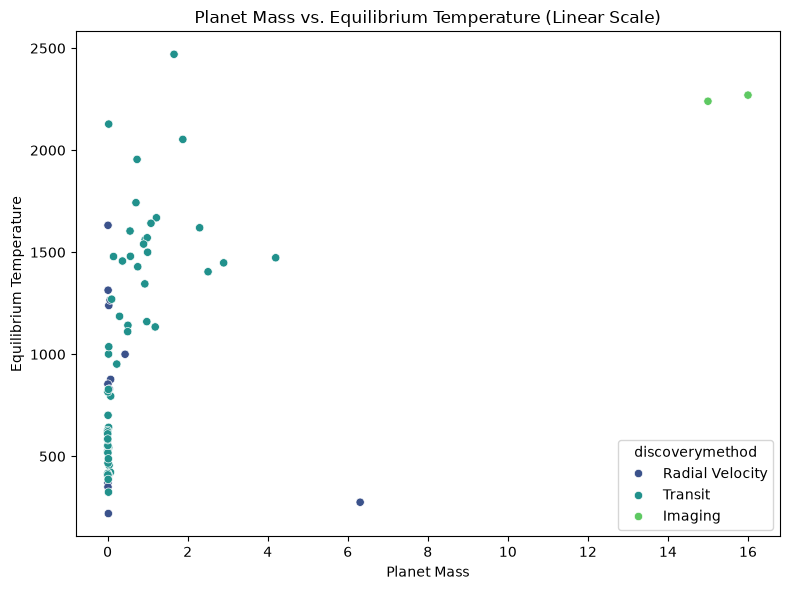

In [27]:
plot_data = df_filtered
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_data, 
    x='pl_bmassj', 
    y='pl_eqt', 
    hue='discoverymethod', 
    palette='viridis'
)
plt.title('Planet Mass vs. Equilibrium Temperature (Linear Scale)')
plt.xlabel('Planet Mass')
plt.ylabel('Equilibrium Temperature')
plt.tight_layout()
plt.show()

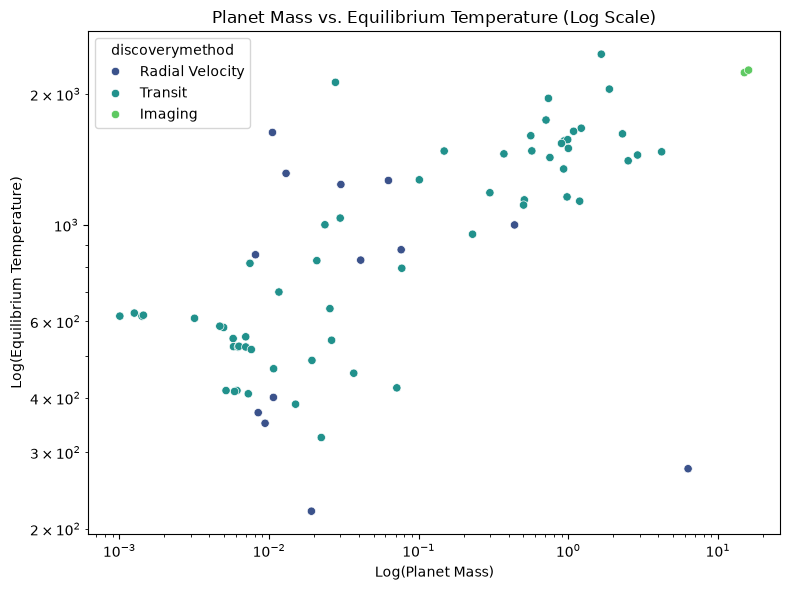

In [26]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_data, 
    x='pl_bmassj', 
    y='pl_eqt', 
    hue='discoverymethod', 
    palette='viridis'
)
plt.xscale('log')
plt.yscale('log')
plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('Log(Planet Mass)')
plt.ylabel('Log(Equilibrium Temperature)')
plt.tight_layout()
plt.show()

In [29]:
#based on the imaging they ar emore likely to be large, they are the bright green dots

In [30]:
massive_planets = df[df['pl_bmassj'] > 5]
coldest_idx = massive_planets['pl_eqt'].idxmin()
coldest_massive_planet = massive_planets.loc[coldest_idx]

print("The coldest massive planet (>5 Jupiter Masses) is:")
print(coldest_massive_planet[['pl_name', 'pl_bmassj', 'pl_eqt']])


The coldest massive planet (>5 Jupiter Masses) is:
pl_name      eps Ind A b
pl_bmassj           6.31
pl_eqt             275.0
Name: 593, dtype: object


In [32]:
print(coldest_massive_planet)

planet_name = coldest_massive_planet['pl_name']
planet_index = coldest_idx
planet_temp = coldest_massive_planet['pl_eqt'] 
planet_mass = coldest_massive_planet['pl_bmassj'] 
star_type = coldest_massive_planet['st_spectype'] 

print(f"\nPlanet Name: {planet_name}")
print(f"DataFrame Index: {planet_index}")
print(f"Equilibrium Temperature: {planet_temp} K")
print(f"Mass (Jupiter Masses): {planet_mass}")
print(f"Host Star Spectral Type: {star_type}")


pl_name           eps Ind A b
hostname            eps Ind A
default_flag                0
sy_snum                     3
sy_pnum                     1
                     ...     
sy_gaiamagerr1       0.007374
sy_gaiamagerr2      -0.007374
rowupdate          2024-08-07
pl_pubdate            2024-09
releasedate        2024-08-07
Name: 593, Length: 92, dtype: object

Planet Name: eps Ind A b
DataFrame Index: 593
Equilibrium Temperature: 275.0 K
Mass (Jupiter Masses): 6.31
Host Star Spectral Type: K5 V


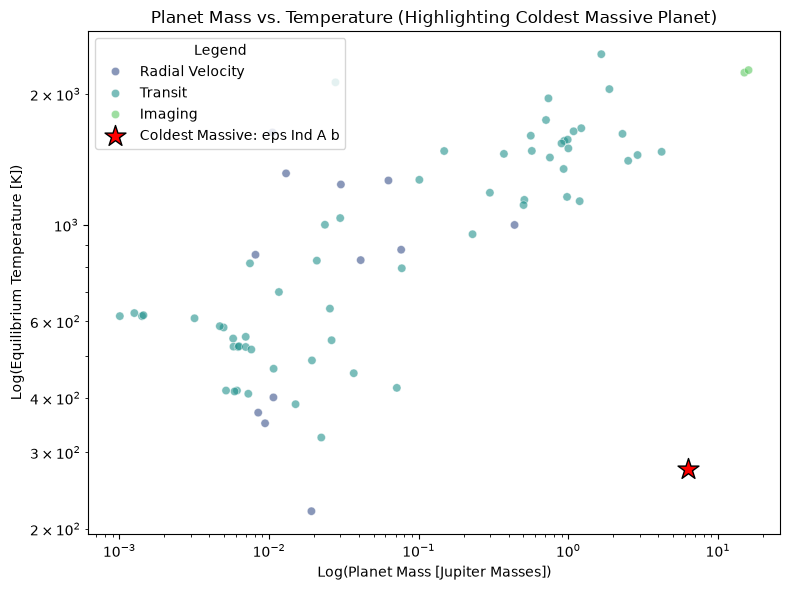

In [36]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=plot_data, 
    x='pl_bmassj', 
    y='pl_eqt', 
    hue='discoverymethod', 
    palette='viridis',
    alpha=0.6 
)

plt.scatter(
    x=coldest_massive_planet['pl_bmassj'],       # X coordinate
    y=coldest_massive_planet['pl_eqt'],          # Y coordinate
    color='red',                                 # Distinct color
    marker='*',                                  # Distinct star marker
    s=250,                                       # Visibly larger size
    edgecolor='black',                           # High-contrast border
    label=f"Coldest Massive: {planet_name}"      # Label for legend
)

plt.xscale('log')
plt.yscale('log')
plt.title('Planet Mass vs. Temperature (Highlighting Coldest Massive Planet)')
plt.xlabel('Log(Planet Mass [Jupiter Masses])')
plt.ylabel('Log(Equilibrium Temperature [K])')
plt.legend(title='Legend', loc='upper left')
plt.tight_layout()
plt.show()


In [37]:
# A temperate super-Jupiter imaged with JWST in the mid-infrared
# This paper details this really big and cold and bright planet that we pinpointed in teh data above, it is really bright and has a high metallicity due to its change in opacity
# My answer matches the planet described in the paper
# as stated above this planet is remarkably cold and bright compared to others
# teh temp and mass are close to what was reported in the paper give or take a factor of 10